# GDGoC UGM Academic Hacker 2026/2027 — Prediksi Diagnosis Pasien (4 Kelas)

**Tugas:** memprediksi `target_class` ∈ {`viral_sinusitis`, `viral_pharyngitis`, `acute_bronchitis`, `strep_pharyngitis`}
dari data rekam medis relasional (multi-CSV). **Metrik:** Macro-F1.

## Ringkasan pendekatan
1. **Relational join per kunjungan** — semua tabel digabung ke level `(patient_id, encounter_id)` dan diagregasi menjadi satu baris fitur.
2. **Data cleaning** — data sengaja "kotor": satuan campur (kPa vs mmHg, fraction vs %), desimal koma, outlier ×10, usia sentinel `999`,
   format pendapatan beragam, dan gejala yang ditulis dengan **parafrase sinonim** (118 varian mentah → 8 konsep kanonik).
3. **Anti-leakage temporal** — setiap catatan riwayat difilter `waktu <= prediction_time` (fungsi `_with_cutoff`) dan diverifikasi secara eksplisit.
4. **Model** — (a) *HistGradientBoosting* dengan bobot kelas lunak, (b) *Regresi Logistik*, (c) *Balanced-Bagging GBDT* (undersampling per bag), dan (d) *MLP PyTorch* dengan embedding kategorikal;
   semuanya 5-fold CV multi-seed. **Imbalance** (strep ≈5%) ditangani dengan tiga mekanisme berbeda (class weight, undersampling, class-weighted loss), lalu **ensemble** dan evaluasi Macro-F1 pada OOF dengan perbandingan bootstrap berpasangan.

## 1. Setup & konfigurasi

In [1]:
import os, re, glob, gc, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import QuantileTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

import torch                                   # deep learning
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 50)

CFG = dict(
    TUNE_NN=False,          # True -> jalankan random search hyperparameter NN (butuh waktu; lebih nyaman di GPU)
    TUNE_NN_TRIALS=12,
    FINAL="ref",            # submission.csv = "ref" (resep LB 0.73455: GBDT-full 0.7 + NN 0.3) | "ens" (GBDT-full + GBDT-lean + LR-lean, tanpa NN)
    DEBUG=False,            # True -> versi mini untuk tes pipeline (hasil JANGAN disubmit)
    SEED=42,
    N_FOLDS=5,
    # --- GBDT
    # hasil random search (35 konfigurasi, diverifikasi pada 3 split berbeda): pohon dangkal + bobot kelas lunak
    GB_SEEDS=[0, 1, 2], GB_ITER=250, GB_LR=0.02, GB_LEAVES=6, GB_DEPTH=3, GB_MIN_LEAF=10, GB_L2=0.0,
    GB_MAX_FEATURES=0.5, GB_BINS=63, GB_CW_POWER=0.5,
    # --- Neural network (PyTorch)
    NN_SEEDS=[0, 1, 2], NN_EPOCHS=60, NN_BATCH=128, NN_LR=2e-3, NN_WD=1e-2,
    NN_HIDDEN=(256, 128), NN_DROPOUT=0.3, NN_IN_DROPOUT=0.1, NN_LABEL_SMOOTH=0.05,
    # --- Logistic Regression & Balanced-Bagging GBDT (penanganan imbalance berbeda)
    LR_C=0.03, LR_CW_POWER=0.5,
    # --- CatBoost
    CB_ITER=600, CB_LR=0.03, CB_DEPTH=4, CB_L2=10, CB_RSM=0.5, CB_WEIGHT_MODES=["Balanced", "SqrtBalanced"],
    BB_CAP=300, BB_BAGS=8,  # tiap bag: maks BB_CAP sampel per kelas (undersampling kelas mayoritas)
    NN_CLASS_W_POWER=0.5,   # bobot kelas = (n / (K * n_c)) ** power ; 0 = tanpa bobot, 1 = penuh
)
if CFG["DEBUG"]:
    CFG.update(N_FOLDS=2, GB_SEEDS=[0], GB_ITER=30, NN_SEEDS=[0], NN_EPOCHS=3, BB_BAGS=2, CB_ITER=30, CB_WEIGHT_MODES=["Balanced"])
    print("DEBUG aktif: hasil TIDAK untuk disubmit.")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__, "| device:", device)

Torch: 2.11.0+cu128 | device: cuda


## 2. Memuat data
Lokasi data dicari otomatis (Kaggle: `/kaggle/input/...`; lokal/PyCharm: folder proyek atau `./data`).
Folder yang dipilih adalah folder yang berisi `index_encounters.csv`, sehingga `train.csv`/`test.csv` yang diambil pasti milik kompetisi ini.

In [2]:
def find_data_root():
    bases = ["/kaggle/input", "./data", ".", ".."]
    for base in bases:
        hits = glob.glob(os.path.join(base, "**", "index_encounters.csv"), recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    # belum diekstrak? cari zip data kompetisi dan ekstrak ke ./data
    import zipfile
    for base in bases:
        for z in glob.glob(os.path.join(base, "*.zip")):
            with zipfile.ZipFile(z) as zf:
                if any(n.endswith("index_encounters.csv") for n in zf.namelist()):
                    zf.extractall("./data")
                    print("Mengekstrak", z, "-> ./data")
                    return find_data_root()
    raise FileNotFoundError("index_encounters.csv tidak ditemukan. Letakkan zip/folder data di ./data atau tambahkan dataset di Kaggle.")

ROOT = find_data_root()
print("DATA_ROOT:", ROOT)

def find_csv(name):
    hits = glob.glob(os.path.join(ROOT, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(name)
    return sorted(hits, key=len)[0]               # path terpendek = paling dekat ke root

train = pd.read_csv(find_csv("train.csv"))
test = pd.read_csv(find_csv("test.csv"))
assert "target_class" in train.columns, "train.csv ini bukan milik kompetisi (tidak ada kolom target_class)"

TABLES = {n: pd.read_csv(find_csv(f"{n}.csv")) for n in [
    "patients", "index_encounters", "triage_vitals", "triage_symptoms", "triage_symptom_severity",
    "presenting_complaints", "previous_encounter", "conditions", "observations",
    "medications", "procedures", "immunizations", "allergies"]}
sample_sub = pd.read_csv(find_csv("sample_submission.csv"))

print("train:", train.shape, "| test:", test.shape)
for n, d in TABLES.items():
    print(f"  {n:26s} {d.shape}")

DATA_ROOT: .
train: (3600, 4) | test: (1400, 3)
  patients                   (5000, 10)
  index_encounters           (5000, 3)
  triage_vitals              (30000, 6)
  triage_symptoms            (19065, 4)
  triage_symptom_severity    (16594, 5)
  presenting_complaints      (5000, 3)
  previous_encounter         (4471, 7)
  conditions                 (3583, 5)
  observations               (55648, 9)
  medications                (3467, 5)
  procedures                 (17024, 6)
  immunizations              (1802, 5)
  allergies                  (2, 10)


## 3. Eksplorasi singkat & pemeriksaan kebocoran

In [3]:
CLASSES = sorted(train["target_class"].unique())
CLASS2ID = {c: i for i, c in enumerate(CLASSES)}
y = train["target_class"].map(CLASS2ID).values
print(train["target_class"].value_counts().to_frame("n").assign(pct=lambda d: (100 * d.n / d.n.sum()).round(1)))
print("\nPasien unik train/test:", train.patient_id.nunique(), test.patient_id.nunique(),
      "| irisan pasien train∩test:", len(set(train.patient_id) & set(test.patient_id)))

                      n   pct
target_class                 
viral_sinusitis    1480  41.1
viral_pharyngitis   985  27.4
acute_bronchitis    940  26.1
strep_pharyngitis   195   5.4

Pasien unik train/test: 3600 1400 | irisan pasien train∩test: 0


In [4]:
# --- Verifikasi anti-leakage temporal: adakah catatan yang waktunya SETELAH prediction_time?
def to_utc(s):
    return pd.to_datetime(s, utc=True, format="ISO8601", errors="coerce")

pt_pat = TABLES["index_encounters"].assign(pt=lambda d: to_utc(d.prediction_time))[["patient_id", "encounter_id", "pt"]]
rows = []
for name, col, key in [("previous_encounter", "history_start", "patient_id"), ("conditions", "recorded_at", "patient_id"),
                       ("medications", "recorded_at", "patient_id"), ("procedures", "recorded_at", "patient_id"),
                       ("observations", "observed_at", "patient_id"), ("immunizations", "recorded_at", "patient_id"),
                       ("allergies", "recorded_at", "patient_id"),
                       ("triage_vitals", "measured_at", "encounter_id"), ("triage_symptoms", "observed_at", "encounter_id")]:
    d = TABLES[name].merge(pt_pat[[key, "pt"]].drop_duplicates(key), on=key)
    t = to_utc(d[col])
    if key == "encounter_id":                      # triase: prediction_time dipotong ke detik, measured_at punya milidetik
        t = t.dt.floor("s")
    rows.append((name, len(d), int((t > d["pt"]).sum())))
print(pd.DataFrame(rows, columns=["tabel", "n_baris", "n_setelah_prediction_time"]))
print("\nTidak ada catatan dari masa depan. Tetap dipasang filter `waktu <= prediction_time` pada semua tabel riwayat (lihat _with_cutoff).")

                tabel  n_baris  n_setelah_prediction_time
0  previous_encounter     4471                          0
1          conditions     3583                          0
2         medications     3467                          0
3          procedures    17024                          0
4        observations    55648                          0
5       immunizations     1802                          0
6           allergies        2                          0
7       triage_vitals    30000                          0
8     triage_symptoms    19065                          0

Tidak ada catatan dari masa depan. Tetap dipasang filter `waktu <= prediction_time` pada semua tabel riwayat (lihat _with_cutoff).


In [5]:
# --- Temuan data kotor yang ditangani pada feature engineering
v = TABLES["triage_vitals"].copy()
print("Vital: satuan per jenis ->"); print(v.groupby("vital_name")["unit"].unique().to_string())
print("\nNilai vital bertipe teks/desimal-koma:", int(v["value"].astype(str).str.contains(",").sum()))
p = TABLES["patients"]
print("Usia sentinel (>110):", int((pd.to_numeric(p.age_at_visit, errors='coerce') > 110).sum()),
      "| format pendapatan non-numerik:", int((~p.income_at_visit.astype(str).str.fullmatch(r"[\d.]+|nan")).sum()))
sy = TABLES["triage_symptoms"].symptom_concept
print("Varian gejala: mentah =", sy.nunique(), "-> normalisasi huruf/spasi =", sy.map(lambda x: re.sub(r"[\s_\-]+", " ", str(x)).strip().lower()).nunique(), "-> konsep kanonik = 8 (+other)")

Vital: satuan per jenis ->
vital_name
BMI                             [kg/m2]
Diastolic BP                [mmHg, kPa]
Heart rate            [beats/min, /min]
Respiratory rate    [/min, breaths/min]
SpO2                      [%, fraction]
Systolic BP                 [mmHg, kPa]

Nilai vital bertipe teks/desimal-koma: 112
Usia sentinel (>110): 19 | format pendapatan non-numerik: 690
Varian gejala: mentah = 118 -> normalisasi huruf/spasi = 70 -> konsep kanonik = 8 (+other)


## 4. Feature engineering relasional

**Prinsip:** satu baris per `encounter_id`.
- **Demografi:** usia (sentinel→NaN), pendapatan (parsing `USD 122,462` / `$51,777`), gender, status pernikahan (`Married`→`M`, dst.), ras/etnis/county.
- **Triase:** keluhan utama dan **konsep gejala kanonik** (jumlah mention, ada/tidak, severity max/mean). Tanda vital juga dibersihkan
  (satuan diseragamkan, koreksi outlier ×10, turunan pulse pressure/MAP/shock index), tetapi **ablasi menunjukkan vital tidak memberi sinyal** sehingga tidak dipakai model (lihat 4c).
- **Riwayat medis:** hitungan per jendela waktu (30/90/365 hari), *days since last*, jumlah kode berbeda, dan jenis kunjungan sebelumnya
  (multi-hot kode spesifik dan nilai observasi terakhir juga dibangun, tetapi tidak dipakai di set `lean`) — **semuanya hanya dari catatan sebelum `prediction_time`**.

In [6]:
# ----------------------------------------------------------------------------
# Util
# ----------------------------------------------------------------------------
def to_utc(s):
    return pd.to_datetime(s, utc=True, format="ISO8601", errors="coerce")


def to_num(s):
    """Konversi ke numerik; menangani desimal koma ('18,33' -> 18.33)."""
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False), errors="coerce")


def _norm_text(x):
    return re.sub(r"[\s_\-]+", " ", str(x)).strip().lower()


# ----------------------------------------------------------------------------
# Pemetaan sinonim gejala -> konsep kanonik (data memakai parafrase sebagai noise)
# ----------------------------------------------------------------------------
SYMPTOM_GROUPS = {
    "throat":    ["throat symptoms", "painful swallowing", "throat pain", "throat discomfort", "sore throat"],
    "cough":     ["cough", "persistent cough", "cough symptom", "coughing", "cough / productive"],
    "fever":     ["fever", "raised temperature", "feverish", "febrile feeling", "temperature complaint"],
    "systemic":  ["systemic symptoms", "body malaise", "general malaise", "general fatigue symptoms", "feeling unwell"],
    "nasal":     ["nasal symptoms", "nasal congestion", "nasal complaints", "blocked nose", "stuffy nose"],
    "secretion": ["respiratory secretions", "sputum production", "mucus complaint", "airway secretions", "mucus / discharge"],
    "dyspnea":   ["dyspnea/wheeze", "difficulty breathing", "breathing discomfort", "wheezy feeling",
                  "shortness of breath / wheeze"],
    "headface":  ["head and facial symptoms"],
}
SYMPTOM_MAP = {v: g for g, vs in SYMPTOM_GROUPS.items() for v in vs}
GROUPS = list(SYMPTOM_GROUPS) + ["other"]

# rentang wajar tanda vital (setelah konversi unit ke mmHg, /min, %, kg/m2)
VITAL_RANGE = {
    "Heart rate": (30, 220), "Respiratory rate": (5, 70), "Systolic BP": (60, 260),
    "Diastolic BP": (30, 150), "SpO2": (50, 100), "BMI": (10, 70),
}

In [7]:
# ----------------------------------------------------------------------------
# 1) Demografi + waktu
# ----------------------------------------------------------------------------
def build_demographics(base, patients, index_enc):
    p = patients.copy()
    p["age"] = to_num(p["age_at_visit"])
    p.loc[(p["age"] < 0) | (p["age"] > 110), "age"] = np.nan        # 999 = sentinel
    inc = p["income_at_visit"].astype(str).str.replace(r"[^\d.]", "", regex=True)
    p["income"] = pd.to_numeric(inc.replace("", np.nan), errors="coerce")
    p["log_income"] = np.log1p(p["income"])
    p["income_missing"] = p["income"].isna().astype(int)
    p["age_missing"] = p["age"].isna().astype(int)
    p["gender"] = (p["gender"].astype(str).str.upper().str[0] == "M").astype(int)
    mar = {"MARRIED": "M", "DIVORCED": "D", "SINGLE": "S", "WIDOWED": "W"}
    p["marital"] = p["marital_at_visit"].astype(str).str.strip().str.upper().replace(mar)
    p["marital"] = p["marital"].where(p["marital"].isin(["M", "D", "S", "W"]), "NA")
    p["race"] = p["race"].fillna("NA")
    p["ethnicity"] = p["ethnicity"].fillna("NA")
    p["county"] = p["county"].fillna("NA")
    p["city_missing"] = p["city"].isna().astype(int)
    cols = ["patient_id", "age", "age_missing", "log_income", "income_missing", "gender",
            "marital", "race", "ethnicity", "county", "city_missing"]
    out = base.merge(p[cols], on="patient_id", how="left")

    ix = index_enc.copy()
    ix["pt"] = to_utc(ix["prediction_time"])
    ix["hour"] = ix["pt"].dt.hour
    ix["dow"] = ix["pt"].dt.dayofweek
    ix["month"] = ix["pt"].dt.month
    ix["doy_sin"] = np.sin(2 * np.pi * ix["pt"].dt.dayofyear / 365.25)
    ix["doy_cos"] = np.cos(2 * np.pi * ix["pt"].dt.dayofyear / 365.25)
    out = out.merge(ix[["encounter_id", "pt", "hour", "dow", "month", "doy_sin", "doy_cos"]],
                    on="encounter_id", how="left")
    return out

In [8]:
# ----------------------------------------------------------------------------
# 2) Triase: keluhan, gejala, severity, tanda vital
# ----------------------------------------------------------------------------
def build_complaints(base, pc):
    out = base[["encounter_id"]].merge(pc[["encounter_id", "presenting_complaints_text"]],
                                       on="encounter_id", how="left")
    txt = out["presenting_complaints_text"].fillna("").str.lower().str.replace("reports:", "", regex=False)
    feats = pd.DataFrame({"encounter_id": out["encounter_id"]})
    for key in ["cough", "fever", "throat", "other respiratory"]:
        feats[f"pc_{key.replace(' ', '_')}"] = txt.str.contains(key).astype(int)
    feats["pc_n"] = feats.filter(like="pc_").sum(axis=1)
    return feats


def build_symptoms(base, sym, sev):
    s = sym.copy()
    s["c"] = s["symptom_concept"].map(_norm_text)
    s["g"] = s["c"].map(SYMPTOM_MAP).fillna("other")
    sv = sev.copy()
    sv["c"] = sv["symptom_concept"].map(_norm_text)
    sv["g"] = sv["c"].map(SYMPTOM_MAP).fillna("other")

    ids = base[["encounter_id"]].drop_duplicates()
    cnt = s.pivot_table(index="encounter_id", columns="g", values="c", aggfunc="size", fill_value=0)
    cnt = cnt.reindex(columns=GROUPS, fill_value=0).add_prefix("sym_n_")
    mx = sv.pivot_table(index="encounter_id", columns="g", values="severity_score", aggfunc="max")
    mx = mx.reindex(columns=GROUPS).add_prefix("sev_max_")
    mean = sv.pivot_table(index="encounter_id", columns="g", values="severity_score", aggfunc="mean")
    mean = mean.reindex(columns=GROUPS).add_prefix("sev_mean_")

    f = ids.merge(cnt, on="encounter_id", how="left").merge(mx, on="encounter_id", how="left") \
           .merge(mean, on="encounter_id", how="left")
    for g in GROUPS:
        f[f"sym_has_{g}"] = (f[f"sym_n_{g}"].fillna(0) > 0).astype(int)
    f["sym_total"] = s.groupby("encounter_id").size().reindex(f["encounter_id"]).fillna(0).values
    f["sym_distinct_groups"] = f[[f"sym_has_{g}" for g in GROUPS[:-1]]].sum(axis=1)
    f["sev_overall_mean"] = sv.groupby("encounter_id")["severity_score"].mean().reindex(f["encounter_id"]).values
    f["sev_overall_max"] = sv.groupby("encounter_id")["severity_score"].max().reindex(f["encounter_id"]).values
    f["sev_missing_rate"] = sv.groupby("encounter_id")["severity_score"].apply(lambda x: x.isna().mean()) \
                              .reindex(f["encounter_id"]).values
    # rasio parafrase vs nama kanonik (kadang informatif sebagai pola noise)
    canon = {c for c in ["throat symptoms", "cough", "fever", "systemic symptoms", "nasal symptoms",
                         "respiratory secretions", "dyspnea/wheeze", "head and facial symptoms"]}
    s["is_canon"] = s["c"].isin(canon).astype(int)
    f["sym_canon_ratio"] = s.groupby("encounter_id")["is_canon"].mean().reindex(f["encounter_id"]).values
    return f


def build_vitals(base, vit):
    v = vit.copy()
    v["val"] = to_num(v["value"])
    u = v["unit"].astype(str).str.lower()
    # --- unit harmonization
    kpa = u.eq("kpa") & v["vital_name"].isin(["Systolic BP", "Diastolic BP"])
    v.loc[kpa, "val"] = v.loc[kpa, "val"] * 7.50062
    frac = v["vital_name"].eq("SpO2") & ((u.eq("fraction")) | (v["val"] <= 1.5))
    v.loc[frac, "val"] = v.loc[frac, "val"] * 100
    # --- koreksi typo ×10 lalu buang yang tetap di luar rentang
    for name, (lo, hi) in VITAL_RANGE.items():
        m = v["vital_name"].eq(name)
        x = v.loc[m, "val"]
        x = x.where(~((x > hi) & (x / 10 >= lo) & (x / 10 <= hi)), x / 10)
        x = x.where((x >= lo) & (x <= hi))
        v.loc[m, "val"] = x
    w = v.pivot_table(index="encounter_id", columns="vital_name", values="val", aggfunc="mean")
    w.columns = [f"vit_{c.lower().replace(' ', '_')}" for c in w.columns]
    w = w.reset_index()
    f = base[["encounter_id"]].drop_duplicates().merge(w, on="encounter_id", how="left")
    for c in [c for c in f.columns if c.startswith("vit_")]:
        f[c + "_miss"] = f[c].isna().astype(int)
    f["vit_pulse_pressure"] = f["vit_systolic_bp"] - f["vit_diastolic_bp"]
    f["vit_map"] = f["vit_diastolic_bp"] + (f["vit_systolic_bp"] - f["vit_diastolic_bp"]) / 3
    f["vit_shock_index"] = f["vit_heart_rate"] / f["vit_systolic_bp"]
    f["vit_n_missing"] = f[[c for c in f.columns if c.endswith("_miss")]].sum(axis=1)
    return f

In [9]:
# ----------------------------------------------------------------------------
# 3) Riwayat medis (dengan temporal cutoff = prediction_time)
# ----------------------------------------------------------------------------
def _with_cutoff(df, base_pt, time_col):
    """Gabungkan prediction_time per pasien dan buang catatan yang waktunya > prediction_time."""
    d = df.merge(base_pt, on="patient_id", how="inner")
    d["t"] = to_utc(d[time_col])
    d["dt"] = (d["pt"] - d["t"]).dt.total_seconds() / 86400.0       # hari sebelum prediction
    return d[(d["dt"] >= 0) & d["t"].notna()]                      # <= prediction_time saja


def _count_windows(d, base, prefix, windows=(30, 90, 365)):
    g = d.groupby("encounter_id")
    f = base[["encounter_id"]].drop_duplicates().copy()
    f[f"{prefix}_n_all"] = f["encounter_id"].map(g.size()).fillna(0)
    for w in windows:
        f[f"{prefix}_n_{w}d"] = f["encounter_id"].map(d[d["dt"] <= w].groupby("encounter_id").size()).fillna(0)
    f[f"{prefix}_days_since_last"] = f["encounter_id"].map(g["dt"].min())
    return f


def _topk_multihot(d, base, code_col, prefix, min_patients=25, max_k=40, recent_days=None):
    """Multi-hot untuk kode paling sering. min_patients ditentukan dari train+test (tanpa label)."""
    x = d if recent_days is None else d[d["dt"] <= recent_days]
    vc = x.groupby(code_col)["patient_id"].nunique().sort_values(ascending=False)
    keep = vc[vc >= min_patients].index[:max_k]
    x = x[x[code_col].isin(keep)]
    m = x.assign(v=1).pivot_table(index="encounter_id", columns=code_col, values="v", aggfunc="max", fill_value=0)
    m.columns = [f"{prefix}_mh_{c}" for c in m.columns]      # penanda "_mh_" = multi-hot kode spesifik
    f = base[["encounter_id"]].drop_duplicates().merge(m.reset_index(), on="encounter_id", how="left")
    return f.fillna(0)


def build_history(base, tables):
    pt = base[["patient_id", "encounter_id", "pt"]].drop_duplicates()
    feats = [base[["encounter_id"]].drop_duplicates()]

    # ---- previous_encounter
    pe = _with_cutoff(tables["previous_encounter"], pt, "history_start")
    f = _count_windows(pe, base, "enc")
    stop = to_utc(pe["history_stop"])
    dur = (stop - pe["t"]).dt.total_seconds() / 60.0
    pe = pe.assign(dur_min=dur.where(stop <= pe["pt"]))             # stop setelah prediction_time -> NaN
    f["enc_mean_dur_min"] = f["encounter_id"].map(pe.groupby("encounter_id")["dur_min"].mean())
    for typ in ["ambulatory", "wellness", "outpatient", "urgentcare", "emergency", "inpatient"]:
        sub = pe[pe["history_type"].astype(str).str.lower() == typ]
        f[f"enc_{typ}_365"] = f["encounter_id"].map(sub.groupby("encounter_id").size()).fillna(0)
        f[f"enc_{typ}_90"] = f["encounter_id"].map(sub[sub["dt"] <= 90].groupby("encounter_id").size()).fillna(0)
    feats.append(f)
    feats.append(_topk_multihot(pe, base, "history_type_code", "enc", min_patients=40, max_k=15))

    # ---- conditions / medications / procedures / immunizations / allergies
    spec = {
        "conditions":    ("recorded_at", "condition_code",   "cond", 30, 40),
        "medications":   ("recorded_at", "medication_code",  "med",  30, 40),
        "procedures":    ("recorded_at", "procedure_code",   "proc", 60, 40),
        "immunizations": ("recorded_at", "immunization_code", "imm", 30, 15),
    }
    for name, (tcol, ccol, prefix, minp, k) in spec.items():
        d = _with_cutoff(tables[name], pt, tcol)
        d[ccol] = d[ccol].astype(str)
        feats.append(_count_windows(d, base, prefix))
        f = base[["encounter_id"]].drop_duplicates().copy()
        f[f"{prefix}_n_distinct"] = f["encounter_id"].map(d.groupby("encounter_id")[ccol].nunique()).fillna(0)
        feats.append(f)
        feats.append(_topk_multihot(d, base, ccol, prefix, min_patients=minp, max_k=k))
    al = _with_cutoff(tables["allergies"], pt, "recorded_at")
    f = base[["encounter_id"]].drop_duplicates().copy()
    f["allergy_n"] = f["encounter_id"].map(al.groupby("encounter_id").size()).fillna(0)
    feats.append(f)

    # ---- observations (lab/vital riwayat): nilai terakhir tiap kode numerik utama + hitungan
    ob = _with_cutoff(tables["observations"], pt, "observed_at")
    ob["num"] = to_num(ob["value"])
    f = _count_windows(ob, base, "obs")
    feats.append(f)
    top = ob[ob["value_type"].astype(str).eq("numeric")].groupby("observation_code")["patient_id"] \
        .nunique().sort_values(ascending=False)
    top = top[top >= 100].index[:12]
    last = ob[ob["observation_code"].isin(top)].sort_values("dt").groupby(["encounter_id", "observation_code"]) \
        .first()["num"].unstack()
    last.columns = [f"obs_last_{c}" for c in last.columns]
    feats.append(base[["encounter_id"]].drop_duplicates().merge(last.reset_index(), on="encounter_id", how="left"))

    out = feats[0]
    for f in feats[1:]:
        out = out.merge(f, on="encounter_id", how="left")
    return out

In [10]:
# ----------------------------------------------------------------------------
# Orkestrasi
# ----------------------------------------------------------------------------
def build_all(train, test, tables):
    """
    train: DataFrame(sample_id, patient_id, encounter_id, target_class)
    test : DataFrame(sample_id, patient_id, encounter_id)
    tables: dict nama -> DataFrame (patients, index_encounters, triage_*, presenting_complaints, riwayat medis ...)
    return: X_all (train + test), n_train
    """
    base = pd.concat([train.drop(columns=["target_class"]), test], ignore_index=True)
    base = build_demographics(base, tables["patients"], tables["index_encounters"])

    X = base.copy()
    for f in [
        build_complaints(base, tables["presenting_complaints"]),
        build_symptoms(base, tables["triage_symptoms"], tables["triage_symptom_severity"]),
        build_vitals(base, tables["triage_vitals"]),
        build_history(base, tables),
    ]:
        X = X.merge(f, on="encounter_id", how="left")
    X = X.drop(columns=["pt"])
    return X, len(train)

In [11]:
X_all, N_TRAIN = build_all(train, test, TABLES)
print("Matriks fitur (train+test):", X_all.shape)
assert (X_all["encounter_id"].values == pd.concat([train.encounter_id, test.encounter_id]).values).all()   # urutan baris terjaga
X_all.iloc[:, :14].head()

Matriks fitur (train+test): (5000, 235)


,sample_id,patient_id,encounter_id,age,age_missing,log_income,income_missing,gender,marital,race,ethnicity,county,city_missing,hour
0,S597603,P3356d7bff677beb583d0,E5d0acd3d0abb3bfbfefe,53.332869,0,11.008960,0,0,D,asian,nonhispanic,Norfolk County,0,19
1,S275201,P8d749c56edb8c5038899,Efcae38d62cb7d9cb3c87,19.609703,0,11.711522,0,1,NA,asian,nonhispanic,NA,0,10
2,S104926,P0691f61cdc03ab2c662d,E8069244880e6813ab1e7,54.985103,0,4.644391,0,1,D,asian,nonhispanic,Norfolk County,1,7
3,S899544,P5ae06f68e8855b41ec48,Ee5094abd24b1a870ef1d,11.921024,0,9.540795,0,1,NA,hawaiian,nonhispanic,Essex County,1,3
4,S733228,P7d1137a3daf05934329c,E689c96845bc278663e68,23.497638,0,10.661931,0,0,NA,white,nonhispanic,NA,0,12


### 4c. Audit & ablasi feature engineering (apakah ada perlakuan yang terlalu spesifik?)
Tiap kelompok fitur dihapus satu per satu lalu dievaluasi dengan 5-fold × 3 split berbeda pada GBDT dan Regresi Logistik (perbandingan berpasangan pada split yang sama).
Selain Macro-F1 (berisik, sd bootstrap ≈0.01) dipakai **macro one-vs-rest AUC** yang jauh lebih stabil (sd antar-split ≈0.0003).

| Kelompok yang dihapus | ΔF1 (GBDT) | ΔAUC (GBDT) | ΔAUC (LR) | Kesimpulan |
|---|---|---|---|---|
| severity gejala (`sev_*`) | −0.034 | −0.010 | −0.010 | **sinyal terbesar** |
| riwayat medis (semua) | −0.011 | −0.005 | −0.003 | **sinyal nyata**, tersebar (proksi kondisi/umur pasien) |
| hitungan gejala (`sym_n_*`, total, distinct) | +0.001 | −0.001 | −0.004 | berguna |
| keluhan utama (`pc_*`) | −0.001 | +0.000 | −0.000 | netral (redundan dengan gejala) |
| tanda vital (semua) + turunannya | −0.000 | +0.000 | +0.001 | **tanpa sinyal** → cleaning rumit tidak berguna |
| demografi kategorikal (ras/etnis/county/marital) | +0.003 | +0.000 | +0.000 | tanpa sinyal |
| income, city_missing | −0.002 | +0.000 | +0.001 | tanpa sinyal |
| fitur "artefak noise" (`sym_canon_ratio`, `*_miss`, dll.) | −0.002 | +0.000 | +0.001 | tanpa sinyal |

Pengujian lanjutan: dari riwayat, **hitungan/recency saja** (48 kolom) sama baiknya atau lebih baik daripada ditambah 94 kolom multi-hot kode spesifik dan nilai observasi terakhir.
Set **`lean` (93 kolom)** vs lengkap (225 kolom): GBDT F1 0.727 vs 0.720 tetapi **AUC praktis sama** (0.9485 vs 0.9480) — jadi keunggulan F1 pada GBDT lebih mungkin noise di batas keputusan daripada peningkatan kualitas probabilitas; Regresi Logistik F1 0.720 vs 0.705 dan AUC 0.944 vs 0.941 (peningkatan nyata, LR lebih sensitif terhadap fitur noise). Karena itu LEAN dipakai untuk LR dan sebagai *pendamping* GBDT, **bukan** pengganti GBDT-full.
Pemetaan sinonim gejala divalidasi: penyimpangan profil kelas tiap varian dari grupnya rata-rata hanya 0.04 (setara noise sampling) dan severity per varian seragam dalam grup — jadi pengelompokan tidak berlebihan.
Nilai vital yang kosong (BMI ≈38%, lainnya ≈6%) murni missing acak dan proporsinya sama antar kelas.

### 4b. Persiapan matriks model
- Buang kolom ID, kolom waktu kalender (split acak ⇒ tidak membantu; uji CV tidak menunjukkan peningkatan), kolom kosong/konstan, dan. Dibuat dua *view*: **FULL** (semua fitur; dipakai GBDT utama dan NN — resep awal) dan **LEAN** (tanpa kelompok yang tidak bersinyal menurut ablasi 4c; dipakai Regresi Logistik dan GBDT pendamping).
- **GBDT**: pakai fitur apa adanya (NaN ditangani native, kategori sebagai `category`).
- **Neural network**: imputasi median + indikator NaN + `QuantileTransformer` → distribusi ≈ normal. *Preprocessor di-fit hanya pada data latih tiap fold.*

In [12]:
ID_COLS = ["sample_id", "patient_id", "encounter_id"]
DROP_TIME = ["hour", "dow", "month", "doy_sin", "doy_cos"]
CAT_COLS = ["marital", "race", "ethnicity", "county"]

cols = [c for c in X_all.columns if c not in ID_COLS + DROP_TIME]
cols = [c for c in cols if X_all[c].notna().any() and X_all[c].nunique(dropna=True) > 1]
CAT = [c for c in CAT_COLS if c in cols]
NUM = [c for c in cols if c not in CAT]

# --- kategori -> indeks integer (kategori langka -> 'rare'); tidak memakai label
CAT_CODES, CAT_SIZES = {}, []
for c in CAT:
    s = X_all[c].astype(str)
    s = s.where(s.map(s.value_counts()) >= 20, "rare")
    cats = sorted(s.unique())
    CAT_CODES[c] = s.map({v: i for i, v in enumerate(cats)}).values.astype("int64")
    CAT_SIZES.append(len(cats))
X_cat = np.stack([CAT_CODES[c] for c in CAT], axis=1) if CAT else np.zeros((len(X_all), 0), dtype="int64")
X_num_df = X_all[NUM].reset_index(drop=True)

# --- matriks untuk GBDT (kategori sebagai dtype category di seluruh baris agar kode konsisten)
X_gb = X_all[NUM + CAT].reset_index(drop=True).copy()
for c in CAT:
    X_gb[c] = X_gb[c].astype(str).astype("category")


class NumPrep:
    """Imputasi median + indikator NaN + QuantileTransformer. fit() hanya pada data latih fold."""
    def __init__(self, na_thresh=0.01):
        self.na_thresh = na_thresh

    def fit(self, df):
        self.med = df.median().fillna(0)
        na_rate = df.isna().mean()
        self.na_cols = [c for c in df.columns if self.na_thresh <= na_rate[c] < 0.999]
        self.binary = [c for c in df.columns if set(df[c].dropna().unique()) <= {0, 1, 0.0, 1.0}]
        self.cont = [c for c in df.columns if c not in self.binary]
        self.qt = QuantileTransformer(n_quantiles=min(200, len(df)), output_distribution="normal",
                                      subsample=10**9, random_state=0)
        self.qt.fit(df.fillna(self.med)[self.cont])
        return self

    def transform(self, df):
        filled = df.fillna(self.med)
        cont = self.qt.transform(filled[self.cont])
        bi = filled[self.binary].values.astype("float32")
        na = df[self.na_cols].isna().values.astype("float32")
        return np.hstack([cont.astype("float32"), bi, na])

Xg_tr, Xg_te = X_gb.iloc[:N_TRAIN], X_gb.iloc[N_TRAIN:]
Xn_tr, Xn_te = X_num_df.iloc[:N_TRAIN].reset_index(drop=True), X_num_df.iloc[N_TRAIN:].reset_index(drop=True)
Xc_tr, Xc_te = X_cat[:N_TRAIN], X_cat[N_TRAIN:]

# --- VIEW LEAN (hasil ablasi 4c): buang kelompok tanpa sinyal. Dipakai untuk model yang sensitif terhadap noise (Regresi Logistik)
#     dan sebagai GBDT pendamping. VIEW FULL tetap dipakai GBDT utama & NN (resep awal yang memberi LB 0.73455).
LEAN_DROP = set(CAT_COLS) | {"log_income", "income_missing", "city_missing", "age_missing", "sym_canon_ratio", "sev_missing_rate"}
LEAN_DROP |= {c for c in NUM if c.startswith(("vit_", "obs_last_")) or "_mh_" in c}      # vital, observasi terakhir, multi-hot kode riwayat
LEAN_NUM = [c for c in NUM if c not in LEAN_DROP]
Xl_all = X_all[LEAN_NUM].reset_index(drop=True)
Xl_tr, Xl_te = Xl_all.iloc[:N_TRAIN].reset_index(drop=True), Xl_all.iloc[N_TRAIN:].reset_index(drop=True)
print(f"VIEW LEAN: {len(LEAN_NUM)} fitur numerik (VIEW FULL: {len(NUM)} numerik + {len(CAT)} kategorikal)")

VIEW LEAN: 93 fitur numerik (VIEW FULL: 221 numerik + 4 kategorikal)


## 5. Model A — Gradient Boosting (HistGradientBoosting)
Imbalance ditangani dengan `sample_weight` = (n / (K·n_c))^0.5 (bobot kelas lunak; hasil tuning menunjukkan `balanced` penuh terlalu agresif). Hyperparameter hasil *random search* 2 tahap (35 konfigurasi pada satu split → 5 kandidat teratas diuji ulang pada 3 split lain): pohon dangkal (depth 3, 6 leaf), learning rate kecil, `max_features=0.5` — baseline lama ≈0.709 → ≈0.72 Macro-F1. 5-fold stratified CV × beberapa seed (variasi lewat split berbeda dan `max_features`).
Setiap seed menghasilkan prediksi **out-of-fold (OOF)** utuh; hasilnya dirata-rata.

In [13]:
K = len(CLASSES)

def macro_f1(y_true, proba):
    return f1_score(y_true, proba.argmax(1), average="macro")

cls_w_gb = (N_TRAIN / (len(CLASSES) * np.bincount(y))) ** CFG["GB_CW_POWER"]      # bobot kelas lunak (0.5 = akar balanced)

def run_gbdt_cv(Xtr, Xte, tag="GBDT"):
    oof = np.zeros((N_TRAIN, K)); te = np.zeros((len(Xte), K))
    for s in CFG["GB_SEEDS"]:
        skf = StratifiedKFold(CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"] + s)
        oof_s = np.zeros((N_TRAIN, K))
        for a, b in skf.split(Xtr, y):
            m = HistGradientBoostingClassifier(
                max_iter=CFG["GB_ITER"], learning_rate=CFG["GB_LR"], max_leaf_nodes=CFG["GB_LEAVES"],
                max_depth=CFG["GB_DEPTH"], min_samples_leaf=CFG["GB_MIN_LEAF"], l2_regularization=CFG["GB_L2"],
                max_features=CFG["GB_MAX_FEATURES"], max_bins=CFG["GB_BINS"],
                categorical_features="from_dtype", early_stopping=False, random_state=s)
            m.fit(Xtr.iloc[a], y[a], sample_weight=cls_w_gb[y[a]])
            oof_s[b] = m.predict_proba(Xtr.iloc[b])
            te += m.predict_proba(Xte) / (CFG["N_FOLDS"] * len(CFG["GB_SEEDS"]))
        print(f"  {tag} seed {s}: OOF macro-F1 = {macro_f1(y, oof_s):.4f}")
        oof += oof_s / len(CFG["GB_SEEDS"])
    return oof, te

t0 = time.time()
oof_gb, te_gb = run_gbdt_cv(Xg_tr, Xg_te, "GBDT-full")                       # VIEW FULL (resep awal)
print(f"GBDT-full OOF macro-F1 = {macro_f1(y, oof_gb):.4f}  | per kelas: {np.round(f1_score(y, oof_gb.argmax(1), average=None), 3)}  | {time.time()-t0:.0f}s")
t0 = time.time()
oof_gb_lean, te_gb_lean = run_gbdt_cv(Xl_tr, Xl_te, "GBDT-lean")                # VIEW LEAN (pendamping)
print(f"GBDT-lean OOF macro-F1 = {macro_f1(y, oof_gb_lean):.4f}  | per kelas: {np.round(f1_score(y, oof_gb_lean.argmax(1), average=None), 3)}  | {time.time()-t0:.0f}s")

  GBDT-full seed 0: OOF macro-F1 = 0.7206
  GBDT-full seed 1: OOF macro-F1 = 0.7223
  GBDT-full seed 2: OOF macro-F1 = 0.7131
GBDT-full OOF macro-F1 = 0.7208  | per kelas: [0.862 0.378 0.728 0.915]  | 44s
  GBDT-lean seed 0: OOF macro-F1 = 0.7282
  GBDT-lean seed 1: OOF macro-F1 = 0.7335
  GBDT-lean seed 2: OOF macro-F1 = 0.7286
GBDT-lean OOF macro-F1 = 0.7342  | per kelas: [0.863 0.419 0.739 0.916]  | 23s


## 5b. Model B — Regresi Logistik (model linear)
Data ini dihasilkan oleh proses sintetis, dan model linear ternyata **sangat kompetitif** (≈0.715 OOF) dengan F1 kelas strep setara/lebih baik dari GBDT.
Ia juga berbeda keluarga dari pohon/NN sehingga menambah keragaman ensemble. Imbalance: `class_weight` = (n / (K·n_c))^0.5; `C=0.03` dipilih dari grid {0.003…0.1}.
Memakai **VIEW LEAN** (tanpa fitur noise): ablasi menunjukkan LR jauh lebih sensitif terhadap fitur tanpa sinyal daripada pohon (AUC +0.003 bila dibuang). Preprocessing `NumPrep` di-fit per fold.

In [14]:
cls_w_lr = {i: float(w) for i, w in enumerate((N_TRAIN / (K * np.bincount(y))) ** CFG["LR_CW_POWER"])}

def run_lr_cv(Xtr, Xte):
    oof = np.zeros((N_TRAIN, K)); te = np.zeros((len(Xte), K))
    for s in CFG["GB_SEEDS"]:
        skf = StratifiedKFold(CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"] + 300 + s)
        oof_s = np.zeros((N_TRAIN, K))
        for a, b in skf.split(Xtr, y):
            prep = NumPrep().fit(Xtr.iloc[a])                                  # fit HANYA pada data latih fold
            A, B, T = prep.transform(Xtr.iloc[a]), prep.transform(Xtr.iloc[b]), prep.transform(Xte)
            m = LogisticRegression(C=CFG["LR_C"], class_weight=cls_w_lr, max_iter=3000).fit(A, y[a])
            oof_s[b] = m.predict_proba(B)
            te += m.predict_proba(T) / (CFG["N_FOLDS"] * len(CFG["GB_SEEDS"]))
        oof += oof_s / len(CFG["GB_SEEDS"])
    return oof, te

t0 = time.time()
oof_lr, te_lr = run_lr_cv(Xl_tr, Xl_te)                                        # VIEW LEAN
print(f"LogReg (lean) OOF macro-F1 = {macro_f1(y, oof_lr):.4f}  | per kelas: {np.round(f1_score(y, oof_lr.argmax(1), average=None), 3)}  | {time.time()-t0:.0f}s")

LogReg (lean) OOF macro-F1 = 0.7177  | per kelas: [0.853 0.384 0.719 0.914]  | 11s


## 5c. Model C — Balanced-Bagging GBDT (imbalance lewat undersampling)
Pendekatan imbalance yang **berbeda secara struktural** dari class weight (gaya *EasyEnsemble*): setiap bag mengambil maksimal `BB_CAP`=300 sampel per kelas
(semua strep ≈156 per fold-latih, kelas besar disubsampel), melatih GBDT dangkal, lalu probabilitas dirata-rata atas `BB_BAGS` bag.
Hasil uji: F1 kelas strep **tertinggi** (≈0.41) walau skor total sedikit di bawah GBDT berbobot, sehingga melengkapi ensemble. Cap yang lebih besar (500) lebih buruk (strep ≈0.33).

In [15]:
def run_bbgb_cv():
    oof = np.zeros((N_TRAIN, K)); te = np.zeros((len(Xg_te), K))
    for s in CFG["GB_SEEDS"]:
        skf = StratifiedKFold(CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"] + 200 + s)
        oof_s = np.zeros((N_TRAIN, K))
        for f_i, (a, b) in enumerate(skf.split(Xg_tr, y)):
            rng = np.random.RandomState(1000 * s + f_i)
            ya = y[a]
            for k in range(CFG["BB_BAGS"]):
                sel = np.concatenate([rng.choice(np.where(ya == c)[0], size=min(CFG["BB_CAP"], int((ya == c).sum())), replace=False)
                                      for c in range(K)])
                m = HistGradientBoostingClassifier(
                    max_iter=150, learning_rate=0.03, max_leaf_nodes=6, max_depth=3, min_samples_leaf=10, l2_regularization=0.0,
                    max_features=0.5, max_bins=63, categorical_features="from_dtype", early_stopping=False, random_state=k)
                m.fit(Xg_tr.iloc[a[sel]], y[a[sel]])
                oof_s[b] += m.predict_proba(Xg_tr.iloc[b]) / CFG["BB_BAGS"]
                te += m.predict_proba(Xg_te) / (CFG["N_FOLDS"] * len(CFG["GB_SEEDS"]) * CFG["BB_BAGS"])
        oof += oof_s / len(CFG["GB_SEEDS"])
    return oof, te

t0 = time.time()
oof_bb, te_bb = run_bbgb_cv()
print(f"Balanced-Bagging GBDT OOF macro-F1 = {macro_f1(y, oof_bb):.4f}  | per kelas: {np.round(f1_score(y, oof_bb.argmax(1), average=None), 3)}  | {time.time()-t0:.0f}s")

Balanced-Bagging GBDT OOF macro-F1 = 0.7158  | per kelas: [0.854 0.407 0.693 0.91 ]  | 95s


## 5d. Model D — CatBoost (StratifiedKFold + class weight *Balanced*)
CatBoost dengan **fitur kategorikal native** (`marital`, `race`, `ethnicity`, `county` sebagai string, diolah *ordered target statistics* — tanpa encoding manual), loss `MultiClass`, dan `StratifiedKFold` (proporsi kelas terjaga di tiap fold; strep ≈5% ⇒ ±39 sampel per fold-validasi).

Imbalance lewat `auto_class_weights`:
- **`Balanced`** — bobot kelas = n_max / n_c (strep mendapat bobot terbesar; paling agresif),
- **`SqrtBalanced`** — akar dari bobot Balanced (lebih lunak; pada GBDT lain pola ini terbukti lebih baik).

Kedua mode dijalankan dan dilaporkan; yang OOF-nya lebih tinggi ikut ke tahap ensemble. Jumlah iterasi **tetap** (tanpa early stopping pada fold validasi, agar OOF tidak optimistis).
Jika `catboost` belum terpasang (`pip install catboost`), sel ini dilewati dan notebook tetap jalan tanpanya.

In [16]:
CB_RES = {}                                    # {mode: (oof, test)} -> dipakai di tahap ensemble
try:
    from catboost import CatBoostClassifier
    HAS_CB = True
except ImportError:
    HAS_CB = False
    print("catboost belum terpasang -> bagian CatBoost dilewati (pip install catboost)")

if HAS_CB:
    X_cb = X_all[NUM + CAT].reset_index(drop=True).copy()
    for c in CAT:
        X_cb[c] = X_cb[c].astype(str)                                  # kategori sebagai string
    Xcb_tr, Xcb_te = X_cb.iloc[:N_TRAIN], X_cb.iloc[N_TRAIN:]

    def run_cb_cv(weight_mode):
        oof = np.zeros((N_TRAIN, K)); te = np.zeros((len(Xcb_te), K))
        for s in CFG["GB_SEEDS"]:
            skf = StratifiedKFold(CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"] + 400 + s)
            oof_s = np.zeros((N_TRAIN, K))
            for a, b in skf.split(Xcb_tr, y):
                m = CatBoostClassifier(
                    iterations=CFG["CB_ITER"], learning_rate=CFG["CB_LR"], depth=CFG["CB_DEPTH"], l2_leaf_reg=CFG["CB_L2"],
                    rsm=CFG["CB_RSM"], loss_function="MultiClass", auto_class_weights=weight_mode,
                    cat_features=(CAT or None), random_seed=s, thread_count=-1, verbose=0, allow_writing_files=False)
                m.fit(Xcb_tr.iloc[a], y[a])
                oof_s[b] = m.predict_proba(Xcb_tr.iloc[b])
                te += m.predict_proba(Xcb_te) / (CFG["N_FOLDS"] * len(CFG["GB_SEEDS"]))
            print(f"  CatBoost[{weight_mode}] seed {s}: OOF macro-F1 = {macro_f1(y, oof_s):.4f}")
            oof += oof_s / len(CFG["GB_SEEDS"])
        return oof, te

    for mode in CFG["CB_WEIGHT_MODES"]:
        t0 = time.time()
        CB_RES[mode] = run_cb_cv(mode)
        o = CB_RES[mode][0]
        print(f"CatBoost[{mode}] OOF macro-F1 = {macro_f1(y, o):.4f}  | per kelas: {np.round(f1_score(y, o.argmax(1), average=None), 3)}  | {time.time()-t0:.0f}s")

  CatBoost[Balanced] seed 0: OOF macro-F1 = 0.6900
  CatBoost[Balanced] seed 1: OOF macro-F1 = 0.6953
  CatBoost[Balanced] seed 2: OOF macro-F1 = 0.6932
CatBoost[Balanced] OOF macro-F1 = 0.6943  | per kelas: [0.844 0.385 0.64  0.908]  | 295s
  CatBoost[SqrtBalanced] seed 0: OOF macro-F1 = 0.7032
  CatBoost[SqrtBalanced] seed 1: OOF macro-F1 = 0.7051
  CatBoost[SqrtBalanced] seed 2: OOF macro-F1 = 0.7104
CatBoost[SqrtBalanced] OOF macro-F1 = 0.7030  | per kelas: [0.848 0.322 0.729 0.913]  | 351s


## 6. Model E — MLP PyTorch dengan embedding kategorikal
- Input: fitur numerik terkuantisasi-normal + indikator NaN + embedding kategori (`marital`, `race`, `ethnicity`, `county`).
- Arsitektur: `Dropout → [Linear → BatchNorm → SiLU → Dropout] × 2 → Linear(4)`.
- Loss: `CrossEntropy` dengan **class weight** (akar invers frekuensi) + **label smoothing**; optimizer `AdamW` + jadwal `OneCycleLR`; gradient clipping.
- Snapshot epoch terbaik dipilih dari *validation loss* (berbobot sama) pada fold-nya; prediksi test = rata-rata semua fold × seed.

In [17]:
class TabMLP(nn.Module):
    def __init__(self, n_num, cat_sizes, n_classes, hidden=(256, 128), emb_dim=4, dropout=0.3, in_dropout=0.1):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(s, min(emb_dim, s)) for s in cat_sizes])
        d = n_num + sum(min(emb_dim, s) for s in cat_sizes)
        layers = [nn.Dropout(in_dropout)]
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.SiLU(), nn.Dropout(dropout)]
            d = h
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, n_classes)

    def forward(self, x_num, x_cat):
        if len(self.embs) > 0:
            x = torch.cat([x_num] + [emb(x_cat[:, i]) for i, emb in enumerate(self.embs)], dim=1)
        else:
            x = x_num
        return self.head(self.body(x))


@torch.no_grad()
def predict_logits(model, Xn, Xc, bs=1024):
    model.eval()
    out = []
    for i in range(0, len(Xn), bs):
        xn = torch.from_numpy(Xn[i:i + bs]).to(device)
        xc = torch.from_numpy(Xc[i:i + bs]).to(device)
        out.append(model(xn, xc).float().cpu())
    return torch.cat(out)


def fit_nn_fold(Xn_a, Xc_a, y_a, Xn_b, Xc_b, y_b, seed, class_w):
    set_seed(seed)
    model = TabMLP(Xn_a.shape[1], CAT_SIZES, K, CFG["NN_HIDDEN"], 4, CFG["NN_DROPOUT"], CFG["NN_IN_DROPOUT"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["NN_LR"], weight_decay=CFG["NN_WD"])
    loader = DataLoader(TensorDataset(torch.from_numpy(Xn_a), torch.from_numpy(Xc_a), torch.from_numpy(y_a)),
                        batch_size=CFG["NN_BATCH"], shuffle=True, drop_last=True,       # drop_last: BatchNorm butuh batch > 1
                        generator=torch.Generator().manual_seed(seed))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["NN_LR"], epochs=CFG["NN_EPOCHS"],
                                                steps_per_epoch=len(loader), pct_start=0.2)
    crit = nn.CrossEntropyLoss(weight=class_w.to(device), label_smoothing=CFG["NN_LABEL_SMOOTH"])
    yb_t = torch.from_numpy(y_b)
    best_loss, best_ep, best_state = float("inf"), -1, None
    for ep in range(CFG["NN_EPOCHS"]):
        model.train()
        for xn, xc, yy in loader:
            xn, xc, yy = xn.to(device), xc.to(device), yy.to(device)
            opt.zero_grad(set_to_none=True)
            loss = crit(model(xn, xc), yy)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
        v_loss = F.cross_entropy(predict_logits(model, Xn_b, Xc_b), yb_t, weight=class_w).item()
        if v_loss < best_loss:
            best_loss, best_ep = v_loss, ep
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_ep, best_loss


def run_nn_cv():
    counts = np.bincount(y, minlength=K)
    class_w = torch.tensor((N_TRAIN / (K * counts)) ** CFG["NN_CLASS_W_POWER"], dtype=torch.float32)
    print("class weight:", {c: round(float(w), 2) for c, w in zip(CLASSES, class_w)})
    oof = np.zeros((N_TRAIN, K)); te = np.zeros((len(Xn_te), K))
    for s in CFG["NN_SEEDS"]:
        skf = StratifiedKFold(CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"] + 100 + s)
        oof_s = np.zeros((N_TRAIN, K)); eps = []
        for a, b in skf.split(Xn_tr, y):
            prep = NumPrep().fit(Xn_tr.iloc[a])                        # fit HANYA pada data latih fold
            A, B, T = prep.transform(Xn_tr.iloc[a]), prep.transform(Xn_tr.iloc[b]), prep.transform(Xn_te)
            model, best_ep, _ = fit_nn_fold(A, Xc_tr[a], y[a], B, Xc_tr[b], y[b], seed=s, class_w=class_w)
            oof_s[b] = F.softmax(predict_logits(model, B, Xc_tr[b]), dim=1).numpy()
            te += F.softmax(predict_logits(model, T, Xc_te), dim=1).numpy() / (CFG["N_FOLDS"] * len(CFG["NN_SEEDS"]))
            eps.append(best_ep)
            del model; gc.collect()
        print(f"  NN seed {s}: OOF macro-F1 = {macro_f1(y, oof_s):.4f} | best epoch per fold: {eps}")
        oof += oof_s / len(CFG["NN_SEEDS"])
    return oof, te

### 6b. (Opsional) Tuning hyperparameter NN
Set `CFG["TUNE_NN"] = True`. Random search: tiap trial = 5-fold × 1 seed, skor = OOF Macro-F1. Trial terbaik otomatis dipakai untuk run final di bawah.
Catatan: skor OOF dipakai untuk memilih sekaligus melaporkan, jadi sedikit optimistis; bandingkan dengan baseline NN pada seed/split berbeda bila perlu.

In [18]:
def tune_nn(n_trials, seed=0):
    rng = np.random.RandomState(seed)
    base = dict(CFG); results = []
    space_hidden = [(128, 64), (256, 128), (512, 256), (256, 128, 64)]
    for i in range(n_trials):
        trial = dict(
            NN_LR=float(rng.choice([5e-4, 1e-3, 2e-3, 4e-3])), NN_WD=float(rng.choice([1e-3, 1e-2, 5e-2, 1e-1])),
            NN_HIDDEN=space_hidden[rng.randint(len(space_hidden))], NN_DROPOUT=float(rng.choice([0.2, 0.3, 0.4, 0.5])),
            NN_LABEL_SMOOTH=float(rng.choice([0.0, 0.05, 0.1])), NN_CLASS_W_POWER=float(rng.choice([0.25, 0.5, 0.75, 1.0])),
            NN_EPOCHS=int(rng.choice([30, 60, 90])), NN_BATCH=int(rng.choice([64, 128, 256])), NN_SEEDS=[0])
        CFG.update(trial)
        oof_t, _ = run_nn_cv()
        f = macro_f1(y, oof_t); results.append((f, trial))
        print(f"[trial {i + 1}/{n_trials}] macro-F1 = {f:.4f} | {trial}")
    CFG.clear(); CFG.update(base)                                  # kembalikan konfigurasi awal
    results.sort(key=lambda r: -r[0])
    return results

if CFG["TUNE_NN"]:
    n_trials = 2 if CFG["DEBUG"] else CFG["TUNE_NN_TRIALS"]
    nn_results = tune_nn(n_trials)
    best_nn = {k: v for k, v in nn_results[0][1].items() if k != "NN_SEEDS"}     # seed final tetap CFG["NN_SEEDS"]
    CFG.update(best_nn)
    print("\nHyperparameter NN terbaik:", best_nn, "| OOF macro-F1 =", round(nn_results[0][0], 4))

In [19]:
t0 = time.time()
oof_nn, te_nn = run_nn_cv()
print(f"NN (rata-rata seed) OOF macro-F1 = {macro_f1(y, oof_nn):.4f}  | per kelas: {np.round(f1_score(y, oof_nn.argmax(1), average=None), 3)}  | {time.time()-t0:.0f}s")

class weight: {'acute_bronchitis': 0.98, 'strep_pharyngitis': 2.15, 'viral_pharyngitis': 0.96, 'viral_sinusitis': 0.78}
  NN seed 0: OOF macro-F1 = 0.6916 | best epoch per fold: [13, 13, 7, 18, 8]
  NN seed 1: OOF macro-F1 = 0.6991 | best epoch per fold: [10, 14, 7, 8, 21]
  NN seed 2: OOF macro-F1 = 0.7049 | best epoch per fold: [13, 14, 10, 13, 10]
NN (rata-rata seed) OOF macro-F1 = 0.7037  | per kelas: [0.85  0.36  0.697 0.908]  | 117s


## 7. Ensemble & optimasi keputusan untuk Macro-F1
1. **Blend** probabilitas dari beberapa kandidat yang ditentukan di muka. Acuan (**REF**) = resep yang memberi LB 0.73455 (GBDT-full 0.7 + NN 0.3); kandidat **ENS** = GBDT-full + GBDT-lean + LR-lean tanpa NN; varian dengan NN ditampilkan di tabel agar dinilai dengan NN torch asli (keragaman keluarga model + view fitur; pada simulasi latih-2200/uji-1400 gabungan GBDT + LR-lean menaikkan AUC ≈ +0.002 dan menang di semua ulangan). Dua submission disimpan terpisah (`submission_ref.csv`, `submission_ens.csv`); tidak ada pemilihan otomatis berdasarkan OOF tertinggi, karena itu hanya menyeleksi noise. Tidak ada pencarian bobot bebas: simpangan baku Macro-F1 (bootstrap) ≈0.01, sehingga bobot hasil pencarian hanya menyesuaikan noise. Tabel perbandingan memakai **bootstrap berpasangan** terhadap blend acuan agar jelas apakah suatu selisih nyata atau hanya noise.
2. **Skala probabilitas per kelas** (menaikkan kelas minoritas) sudah diuji berulang kali dengan uji split-half dan selalu tidak menguntungkan (kurva Macro-F1 vs pengali strep datar di 1.0–1.2), sehingga tidak dipakai; yang ditampilkan hanya diagnostiknya.

In [20]:
# --- 7a. kandidat ensemble (ditentukan di muka) + OOF macro-F1, AUC (metrik stabil), dan bootstrap berpasangan terhadap acuan
OOF = {"gbdt": oof_gb, "gbdt_lean": oof_gb_lean, "lr_lean": oof_lr, "bb_gbdt": oof_bb, "nn": oof_nn}
TEST = {"gbdt": te_gb, "gbdt_lean": te_gb_lean, "lr_lean": te_lr, "bb_gbdt": te_bb, "nn": te_nn}
for mode, (o_, t_) in CB_RES.items():
    OOF[f"cb_{mode}"], TEST[f"cb_{mode}"] = o_, t_

auc_ovr = lambda P: roc_auc_score(y, P, multi_class="ovr", average="macro")
tab = pd.DataFrame({k: {"macro_f1": macro_f1(y, v), "auc": auc_ovr(v),
                        **{f"f1_{c}": f1_score(y, v.argmax(1), average=None)[i] for i, c in enumerate(CLASSES)}}
                    for k, v in OOF.items()}).T
print(tab.round(4).to_string())
print("\nKorelasi P(strep) antar-model:"); print(pd.DataFrame({k: v[:, CLASS2ID["strep_pharyngitis"]] for k, v in OOF.items()}).corr().round(2))

REF = "REF: gbdt+nn (0.7/0.3)"                     # resep yang memberi LB 0.73455
ENS = "ENS: gbdt+gbdt_lean+lr_lean"                 # tanpa NN: didukung simulasi holdout & AUC OOF
CANDS = {                                          # bobot tiap kandidat berjumlah 1
    "gbdt":                     {"gbdt": 1.0},
    REF:                        {"gbdt": 0.7, "nn": 0.3},
    "gbdt_lean":                {"gbdt_lean": 1.0},
    "lr_lean":                  {"lr_lean": 1.0},
    ENS:                        {"gbdt": 1 / 3, "gbdt_lean": 1 / 3, "lr_lean": 1 / 3},
    "gbdt+gbdt_lean+lr_lean+nn": {"gbdt": 0.25, "gbdt_lean": 0.25, "lr_lean": 0.25, "nn": 0.25},       # bandingkan dgn ENS memakai NN torch asli
}
if CB_RES:                                         # CatBoost: hanya sebagai pembanding di tabel
    cb_best = max((k for k in OOF if k.startswith("cb_")), key=lambda k: macro_f1(y, OOF[k]))
    CANDS["catboost saja"] = {cb_best: 1.0}
    CANDS["gbdt+gbdt_lean+lr_lean+cb"] = {"gbdt": 0.25, "gbdt_lean": 0.25, "lr_lean": 0.25, cb_best: 0.25}
mix = lambda D, w: sum(wt * D[k] for k, wt in w.items())
C_OOF = {n: mix(OOF, w) for n, w in CANDS.items()}
C_TE = {n: mix(TEST, w) for n, w in CANDS.items()}

rng_b = np.random.RandomState(0)
boots = [rng_b.randint(0, N_TRAIN, N_TRAIN) for _ in range(200)]
bf1 = lambda P: np.array([f1_score(y[i], P[i].argmax(1), average="macro") for i in boots])
bauc = lambda P: np.array([roc_auc_score(y[i], P[i], multi_class="ovr", average="macro") for i in boots])
ref_f, ref_a = bf1(C_OOF[REF]), bauc(C_OOF[REF])
rows = []
for n_, P in C_OOF.items():
    df_, da_ = bf1(P) - ref_f, bauc(P) - ref_a
    rows.append((n_, macro_f1(y, P), auc_ovr(P), f1_score(y, P.argmax(1), average=None)[CLASS2ID["strep_pharyngitis"]],
                 df_.mean(), df_.std(), da_.mean(), da_.std()))
cmp_df = pd.DataFrame(rows, columns=["kandidat", "OOF_F1", "AUC", "F1_strep", "dF1_vs_REF", "sd_F1", "dAUC_vs_REF", "sd_AUC"]).set_index("kandidat")
print("\n", cmp_df.round(4).to_string())
print("Catatan: selisih F1 < ~2 sd tidak dapat dibedakan dari noise. AUC jauh lebih stabil: dAUC > 2 sd_AUC = peningkatan kualitas probabilitas yang nyata.")

# --- dua submission bernama jelas (tanpa pemilihan otomatis berdasarkan OOF -> menghindari seleksi pada noise)
FINALS = {"ref": REF, "ens": ENS}
final_name = FINALS[CFG["FINAL"]]
final_oof, final_te = C_OOF[final_name], C_TE[final_name]
print(f"\nSubmission utama (CFG['FINAL']='{CFG['FINAL']}'): {final_name}  -> OOF macro-F1 = {macro_f1(y, final_oof):.4f}")

# --- diagnostik imbalance: seberapa sensitif Macro-F1 terhadap pengali probabilitas kelas strep?
si = CLASS2ID["strep_pharyngitis"]
mult = [0.7, 0.85, 1.0, 1.2, 1.5, 2.0]
row = []
for g in mult:
    Q = final_oof.copy(); Q[:, si] *= g; row.append(macro_f1(y, Q))
print("Macro-F1 vs pengali strep:", {g: round(float(v), 4) for g, v in zip(mult, row)})

                 macro_f1     auc  f1_acute_bronchitis  f1_strep_pharyngitis  f1_viral_pharyngitis  f1_viral_sinusitis
gbdt               0.7208  0.9488               0.8616                0.3781                0.7282              0.9152
gbdt_lean          0.7342  0.9491               0.8626                0.4188                0.7389              0.9163
lr_lean            0.7177  0.9445               0.8535                0.3840                0.7193              0.9141
bb_gbdt            0.7158  0.9470               0.8535                0.4066                0.6928              0.9102
nn                 0.7037  0.9420               0.8503                0.3597                0.6965              0.9084
cb_Balanced        0.6943  0.9418               0.8443                0.3851                0.6399              0.9078
cb_SqrtBalanced    0.7030  0.9450               0.8483                0.3218                0.7287              0.9134

Korelasi P(strep) antar-model:
                

                   precision    recall  f1-score   support

 acute_bronchitis      0.866     0.863     0.864       940
strep_pharyngitis      0.410     0.364     0.386       195
viral_pharyngitis      0.746     0.720     0.733       985
  viral_sinusitis      0.899     0.936     0.917      1480

         accuracy                          0.827      3600
        macro avg      0.730     0.721     0.725      3600
     weighted avg      0.822     0.827     0.824      3600



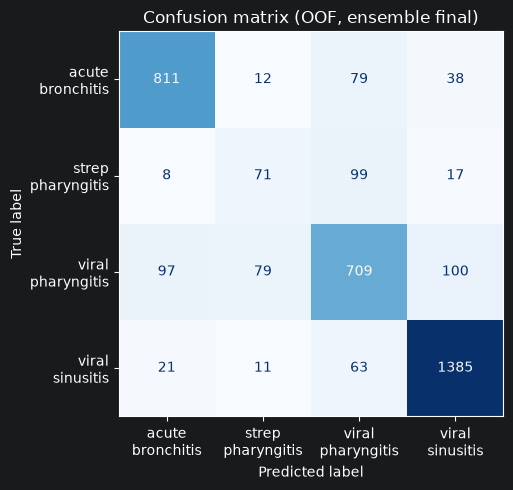

In [21]:
pred_oof = final_oof.argmax(1)
print(classification_report(y, pred_oof, target_names=CLASSES, digits=3))
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_oof), display_labels=[c.replace("_", "\n") for c in CLASSES]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (OOF, ensemble final)"); plt.tight_layout(); plt.show()

## 8. Submission

In [22]:
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

def make_sub(P_te):
    sub = pd.DataFrame({"sample_id": test["sample_id"].values, "target_class": [CLASSES[i] for i in P_te.argmax(1)]})
    assert set(sub.sample_id) == set(sample_sub.sample_id) and len(sub) == len(sample_sub), "sample_id tidak cocok"
    assert sub.target_class.notna().all()
    return sample_sub[["sample_id"]].merge(sub, on="sample_id", how="left")      # urutan sama dengan sample_submission

subs = {k: make_sub(C_TE[v]) for k, v in FINALS.items()}
for k, sdf in subs.items():
    sdf.to_csv(os.path.join(OUT_DIR, f"submission_{k}.csv"), index=False)
subs[CFG["FINAL"]].to_csv(os.path.join(OUT_DIR, "submission.csv"), index=False)       # file utama = pilihan CFG["FINAL"]
np.save(os.path.join(OUT_DIR, "oof_final.npy"), final_oof); np.save(os.path.join(OUT_DIR, "test_final.npy"), final_te)

agree = (subs["ref"].target_class.values == subs["ens"].target_class.values).mean()
print(f"Disimpan: submission_ref.csv, submission_ens.csv, submission.csv (= '{CFG['FINAL']}') di {OUT_DIR}")
print(f"Kesepakatan prediksi test ref vs ens: {agree:.1%}  (selisih {1 - agree:.1%} baris = sumber perbedaan skor LB antar keduanya)")
print(subs[CFG["FINAL"]].target_class.value_counts(normalize=True).round(3).to_string())
subs[CFG["FINAL"]].head()

Disimpan: submission_ref.csv, submission_ens.csv, submission.csv (= 'ref') di .
Kesepakatan prediksi test ref vs ens: 96.6%  (selisih 3.4% baris = sumber perbedaan skor LB antar keduanya)
target_class
viral_sinusitis      0.398
acute_bronchitis     0.276
viral_pharyngitis    0.269
strep_pharyngitis    0.058


,sample_id,target_class
0,S100572,viral_sinusitis
1,S826734,viral_sinusitis
2,S978461,viral_pharyngitis
3,S513298,acute_bronchitis
4,S487893,acute_bronchitis


## 9. Catatan untuk write-up
- **Sinyal utama** ada di severity gejala (ablasi: F1 −0.034 bila dibuang), lalu hitungan gejala dan **riwayat medis** (F1 −0.011, AUC −0.005; sinyalnya tersebar di banyak tabel sehingga tak satu sub-kelompok pun menonjol sendirian). Tanda vital, demografi kategorikal, income, dan fitur artefak noise tidak memberi sinyal; cleaning vital yang rumit ternyata tidak berguna secara prediktif (tetap didokumentasikan sebagai temuan data). Detail di 4c.
- **Kelas tersulit:** `strep_pharyngitis` (minoritas ±5%) sering tertukar dengan `viral_pharyngitis`; pembeda terkuat: ada tidaknya batuk, severity nyeri tenggorokan, dan usia.
- **Noise leaderboard (penting untuk interpretasi skor):** test hanya 1.400 baris (≈76 strep). Simulasi pada subset acak 1.400 baris dari OOF memberi **sd Macro-F1 ≈ 0.013 per skor** (rentang 5–95% ≈ ±0.02), dan F1 strep sd ≈ 0.04. Validasi adversarial train-vs-test: AUC 0.504 (tidak ada pergeseran distribusi). Jadi skor LB 0.7346 (OOF 0.7250, +0.0096) dan 0.7187 sama-sama konsisten dengan performa sebenarnya ≈0.72–0.73; selisih 0.016 antar-submission tidak cukup untuk menyimpulkan satu konfigurasi lebih baik. Keputusan desain sebaiknya memakai OOF + AUC + simulasi holdout berulang, bukan satu angka LB.
- **Imbalance:** kurva Macro-F1 terhadap pengali probabilitas strep datar di sekitar 1.0–1.2 → class weight akar-balanced sudah hampir optimal; pengali yang lebih besar menurunkan skor. Model spesialis strep-vs-viral (AUC 0.78) tidak lebih baik dari model umum (AUC 0.81): batasnya ada pada informasi data (pembeda utama hanya ada tidaknya batuk, severity tenggorokan, usia), bukan pada metode.
- **Model lain yang dicoba:** SVM-RBF (buruk, ≈0.63–0.65), ExtraTrees/RandomForest (0.69/0.70), stacking meta-LR (tidak menambah).
- **Yang dicoba tetapi tidak membantu:** fitur kalender (jam/hari/bulan), multi-hot varian gejala mentah, multi-hot kode riwayat (94 kolom), flag usia anak, dan tuning skala kelas tanpa validasi jujur.
- **Ide lanjutan:** tambah LightGBM/CatBoost/XGBoost ke ensemble, optimasi hyperparameter (Optuna), pseudo-labeling, atau model yang memperlakukan gejala sebagai himpunan (set/attention).